# Starter notebook: Predicting the boiling crisis

This notebook gives you everything except the modeling, so you can start on day one:

| Part | What you get |
|---|---|
| 0 | Setup (installs `pdfplumber` and `iapws` if missing) |
| 1 | **CHF data** (Tasks A–D): builds `chf_nrc.csv` directly from the public NRC PDF (no registration needed), sanity checks, heat balance, exploration, the leakage guard, the fixed splits **S1 / S2 / S3 / low-G**, metric functions (regression, uncertainty, generative), slice and plotting helpers, the common OLS baseline, and the prediction-file writer |
| 2 | **NPPAD** (Task E): download, loading, run-level split, windowing, scaling, classification metrics, a baseline classifier, and the prediction-file writer |

**How to use it.** Run it top to bottom once (a few minutes plus downloads). Skip Part 2 if you are not doing Task E, or Part 1 if you only do Task E. Then build your models below the "Where to go next" cells, or copy the helpers into your own notebook.

**Do not change** the split code, the metric functions or `SEED`. Everybody's numbers must be comparable.

Works in Google Colab and in a local Jupyter environment with Python ≥ 3.9 and `numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib`.

## Part 0. Setup

In [1]:
import sys, subprocess, importlib

def ensure(pkg, module=None):
    # Install a package quietly if it is missing (Colab and local Jupyter).
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        print(f"Installing {pkg} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

ensure("pdfplumber")   # reads the NRC PDF table
ensure("iapws")        # IAPWS-IF97 water properties for the heat balance

In [2]:
import json, re, shutil, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, wasserstein_distance
from sklearn.model_selection import train_test_split, GroupKFold, StratifiedKFold, cross_val_predict
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, roc_auc_score

try:
    display                      # available inside Jupyter / Colab
except NameError:
    display = print

SEED = 2026                      # do not change: defines the shared splits
DATA_DIR = Path("data");    DATA_DIR.mkdir(exist_ok=True)
OUT_DIR  = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

## Part 1. CHF data (Tasks A–D)

### 1.1 Build or load `chf_nrc.csv`

The US NRC publishes the database as a text PDF table ([NUREG/KM-0011 attachment](https://www.nrc.gov/docs/ML2226/ML22264A009.pdf), 6 MB). The cell below downloads it once, parses every data row and saves `data/chf_nrc.csv`. Later runs just load the CSV.

If the download fails (some networks block it), open the link in a browser, save the file as `data/ML22264A009.pdf`, and run the cell again.

In [3]:
NRC_PDF_URL = "https://www.nrc.gov/docs/ML2226/ML22264A009.pdf"
PDF_PATH = DATA_DIR / "ML22264A009.pdf"
CSV_PATH = DATA_DIR / "chf_nrc.csv"

CHF_COLS = ["Number", "DataID", "D_m", "L_m", "P_kPa", "G_kgm2s",
            "X_chf", "DHin_kJkg", "CHF_kWm2", "Tin_C", "Reference"]
NUM = re.compile(r"^-?(\d+\.?\d*|\.\d+)([eE][-+]?\d+)?$")

def parse_line(line):
    # One NRC table row -> list of values, or None for headers, unit lines and footers.
    t = line.split()
    if len(t) < 10 or not t[0].isdigit():
        return None
    vals = t[2:10]
    if not all(NUM.match(v) for v in vals):
        return None
    return [int(t[0]), t[1], *map(float, vals), " ".join(t[10:]).lstrip("*").strip()]

def download(url, path):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (course starter notebook)"})
    with urllib.request.urlopen(req, timeout=180) as r, open(path, "wb") as f:
        f.write(r.read())

def pdf_lines(path):
    try:
        import pdfplumber
        with pdfplumber.open(path) as pdf:
            for page in pdf.pages:
                yield from (page.extract_text() or "").splitlines()
    except ImportError:
        from pypdf import PdfReader
        for page in PdfReader(str(path)).pages:
            yield from (page.extract_text() or "").splitlines()

def build_chf_csv():
    if not PDF_PATH.exists():
        print("Downloading the NRC CHF table (about 6 MB) ...")
        try:
            download(NRC_PDF_URL, PDF_PATH)
        except Exception as e:
            raise RuntimeError(f"Download failed ({e}). Save {NRC_PDF_URL} as {PDF_PATH} "
                               "with your browser and run this cell again.") from e
    print("Parsing the PDF (about a minute) ...")
    rows, rejected = [], []
    for line in pdf_lines(PDF_PATH):
        r = parse_line(line)
        if r:
            rows.append(r)
        elif line.strip()[:1].isdigit() and len(line.split()) >= 5:
            rejected.append(line)          # looks like a data row but did not parse
    out = (pd.DataFrame(rows, columns=CHF_COLS)
             .drop_duplicates("Number").sort_values("Number").reset_index(drop=True))
    out.to_csv(CSV_PATH, index=False)
    print(f"Parsed {len(out)} rows -> {CSV_PATH}. Rejected digit-leading lines: {len(rejected)}")
    for line in rejected[:5]:
        print("   rejected:", line)
    return out

if CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH, dtype={"DataID": str})
else:
    df = build_chf_csv()
    df["DataID"] = df["DataID"].astype(str)

df = df.sort_values("Number").reset_index(drop=True)   # the splits rely on this order
TARGET = "CHF_kWm2"
df.head()

,Number,DataID,D_m,L_m,P_kPa,G_kgm2s,X_chf,DHin_kJkg,CHF_kWm2,Tin_C,Reference
0,1,25,0.004,0.396,100,77.5,0.84,317,442,23.94,Lowdermilk 1958
1,2,26,0.004,0.396,100,142.7,0.79,317,757,23.94,Lowdermilk 1958
2,3,27,0.004,0.396,100,203.9,0.7,317,978,23.94,Lowdermilk 1958
3,4,28,0.004,0.396,100,271.8,0.73,317,1325,23.94,Lowdermilk 1958
4,5,29,0.004,0.396,100,421.3,0.62,317,1798,23.94,Lowdermilk 1958


### 1.2 Sanity checks

You should see about 24.6k rows (the OECD/NEA benchmark version of the same database has 24,579), no missing values, and row 1 = Lowdermilk 1958, *D* = 0.004 m, CHF = 442 kW/m².

In [4]:
EXPECTED_ROWS = 24579
print(f"rows: {len(df)}  (benchmark version: {EXPECTED_ROWS})")
if abs(len(df) - EXPECTED_ROWS) > 0.02 * EXPECTED_ROWS:
    warnings.warn("Row count differs by more than 2% from the benchmark version: inspect the rejected lines above.")

num_cols = CHF_COLS[2:10]
assert df[num_cols].notna().all().all(), "missing numeric values"
assert (df[TARGET] > 0).all(), "non-positive CHF values"

print("row 1:", df.iloc[0][["Number", "D_m", "L_m", "P_kPa", "G_kgm2s", "X_chf",
                            "DHin_kJkg", "CHF_kWm2", "Reference"]].to_dict())
print("experimental sources:", df["Reference"].nunique())
display(df[num_cols].describe().T[["min", "25%", "50%", "75%", "max"]])

rows: 24579  (benchmark version: 24579)
row 1: {'Number': 1, 'D_m': 0.004, 'L_m': 0.396, 'P_kPa': 100.0, 'G_kgm2s': 77.5, 'X_chf': 0.84, 'DHin_kJkg': 317.0, 'CHF_kWm2': 442.0, 'Reference': 'Lowdermilk 1958'}
experimental sources: 349


,min,25%,50%,75%,max
D_m,0.002,0.00787,0.00811,0.01001,0.016
L_m,0.05,1,2,3.658,20
P_kPa,100,5171,9800,1.4e+04,2e+04
G_kgm2s,0,962,1587,2770,7964
X_chf,-0.497,0.158,0.329,0.546,2783
DHin_kJkg,-1211,197,433,683,1644
CHF_kWm2,18,755,1424,2333,1.634e+04
Tin_C,0,117.2,210.3,266.9,361.9


### 1.3 Heat-balance check

For a uniformly heated tube, *q″* = *G D* (*x* *h*<sub>fg</sub> + Δ*h*<sub>in</sub>) / (4 *L*). Almost every row should close within ±5%. `hfg_kJkg` is added to `df` because it is a legitimate physics feature (a function of *P* only). The ratio is kept **outside** `df` on purpose: it contains the target.

row 1 ratio: 0.980  (expected about 0.98)
rows within ±5%: 98.8%


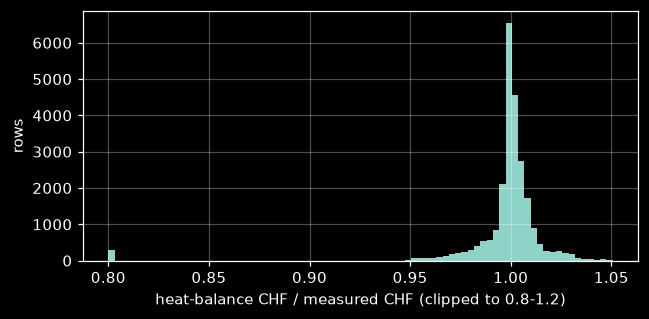

In [5]:
# Fallback steam table (MPa, kJ/kg), used only if iapws is unavailable (about 1-2% error near 20 MPa).
_P_TAB   = np.array([0.1, 0.5, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 14, 16, 18, 20])
_HFG_TAB = np.array([2257.5, 2108.0, 2014.6, 1889.8, 1794.9, 1713.5, 1639.7, 1570.9, 1505.2,
                     1441.6, 1379.3, 1317.6, 1193.6, 1066.5, 930.8, 777.0, 584.2])

_WARNED_HFG = False

def h_fg_kJkg(P_kPa):
    # Latent heat of saturated water at pressure P (kPa), in kJ/kg.
    P = np.asarray(P_kPa, dtype=float) / 1000.0
    try:
        from iapws import IAPWS97
        uniq = np.unique(P)
        hfg = np.array([IAPWS97(P=p, x=1).h - IAPWS97(P=p, x=0).h for p in uniq])
        return hfg[np.searchsorted(uniq, P)]
    except ImportError:
        global _WARNED_HFG
        if not _WARNED_HFG:
            warnings.warn("iapws not installed: using an approximate steam table.")
            _WARNED_HFG = True
        return np.interp(np.log(np.clip(P, 0.1, 20.0)), np.log(_P_TAB), _HFG_TAB)

df["hfg_kJkg"] = h_fg_kJkg(df["P_kPa"])
q_hb = df.G_kgm2s * df.D_m * (df.X_chf * df.hfg_kJkg + df.DHin_kJkg) / (4 * df.L_m)
hb_ratio = (q_hb / df[TARGET]).to_numpy()          # NOT a feature: it uses the target

print(f"row 1 ratio: {hb_ratio[0]:.3f}  (expected about 0.98)")
print(f"rows within ±5%: {100 * np.mean(np.abs(hb_ratio - 1) <= 0.05):.1f}%")

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(np.clip(hb_ratio, 0.8, 1.2), bins=80)
ax.set_xlabel("heat-balance CHF / measured CHF (clipped to 0.8-1.2)"); ax.set_ylabel("rows")
plt.tight_layout(); plt.show()

### 1.4 Quick look at the data

Where are the data dense, and where are they missing? Note the low-*G* region, which matters for natural-circulation SMRs.

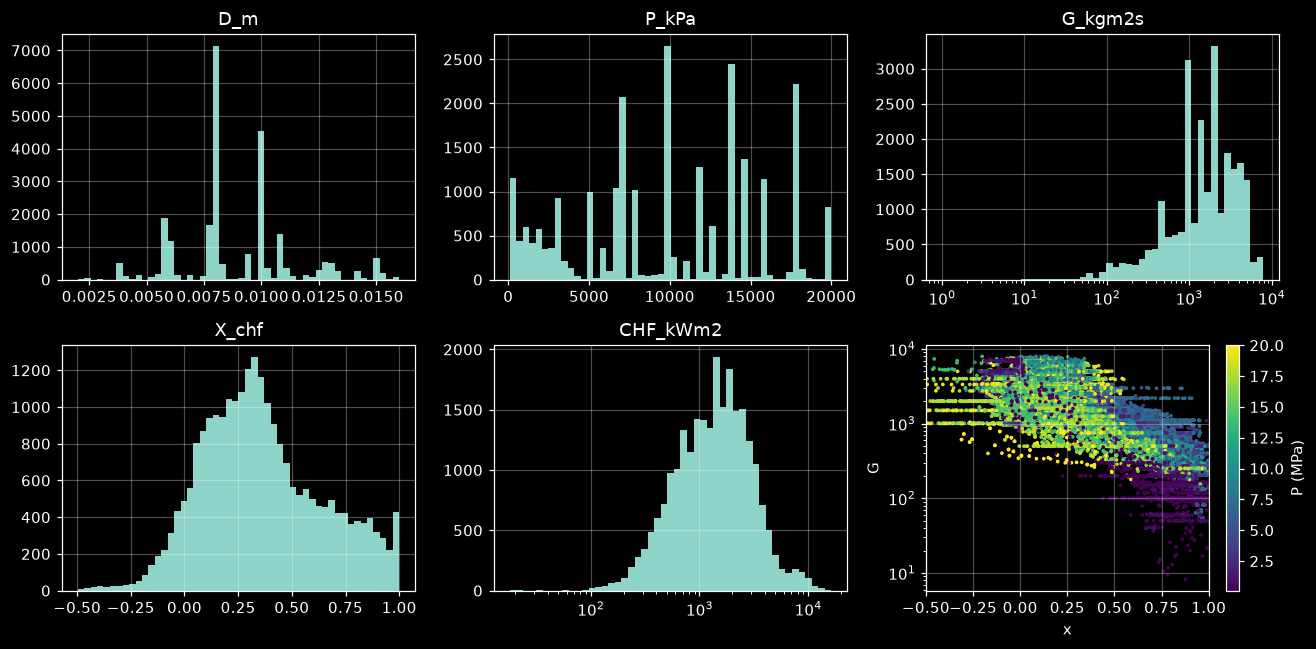

rows with G < 1000: 7108 (28.9%)


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, (col, logx) in zip(axes.flat[:5], [("D_m", False), ("P_kPa", False), ("G_kgm2s", True),
                                           ("X_chf", False), (TARGET, True)]):
    v = df[col].to_numpy()
    if v.min() != 0:
        bins = np.logspace(np.log10(v.min()), np.log10(v.max()), 50) if logx else 50
    else:
        bins = np.logspace(0, np.log10(v.max()), 50) if logx else 50
    if col == "X_chf": v = v.clip(-.5,1) #Some data points out at ~2800 but only a very small amount (probably from just 1 experiment)
    ax.hist(v, bins=bins)
    ax.set_xscale("log" if logx else "linear"); ax.set_title(col)
ax = axes.flat[5]
sc = ax.scatter(df.X_chf, df.G_kgm2s, c=df.P_kPa / 1000, s=2, cmap="viridis")
ax.set_yscale("log"); ax.set_xlabel("x"); ax.set_ylabel("G"); plt.colorbar(sc, ax=ax, label="P (MPa)"); ax.set_xlim(-.5, 1)
plt.tight_layout(); plt.show()

print(f"rows with G < 1000: {(df.G_kgm2s < 1000).sum()} ({100 * (df.G_kgm2s < 1000).mean():.1f}%)")

### 1.5 Feature sets and the leakage guard

`LOCAL` is the required formulation for Tasks A–D. `INLET` is allowed for the comparison in Task A4. `check_features` refuses feature sets that let the heat balance compute CHF exactly (handout, Section 3).

In [7]:
LOCAL = ["P_kPa", "G_kgm2s", "D_m", "X_chf"]               # required in Tasks A-D
INLET = ["P_kPa", "G_kgm2s", "D_m", "L_m", "DHin_kJkg"]     # Task A4 comparison only

def check_features(cols, allow_leaky=False):
    cols = list(cols)
    if TARGET in cols:
        raise ValueError("The target is in the feature list.")
    leaky = "X_chf" in cols and "L_m" in cols and bool({"DHin_kJkg", "Tin_C"} & set(cols))
    if leaky and not allow_leaky:
        raise ValueError("X_chf + L_m + an inlet condition lets the heat balance give CHF exactly. "
                         "Use allow_leaky=True only for the Task A4 demonstration.")
    return cols

def get_xy(idx, cols=LOCAL, log_target=True):
    # Features as float array, target as ln(CHF) (default) or CHF in kW/m2.
    X = df.iloc[idx][check_features(cols)].to_numpy(dtype=float)
    y = df.iloc[idx][TARGET].to_numpy(dtype=float)
    return X, (np.log(y) if log_target else y)

check_features(LOCAL); check_features(INLET); print("feature sets OK")

feature sets OK


### 1.6 The fixed splits

| Split | Purpose | Definition |
|---|---|---|
| **S1** | Interpolation; tuning and main results | random 70 / 15 / 15, `random_state=2026` |
| **S2** | Generalization to an unseen experiment | `GroupKFold(5)` grouped by `Reference`; retrain in every fold |
| **S3** | Extrapolation in mass flux (Tasks B, C) | train/val on *G* < 4000, test on *G* ≥ 4000 |
| **low-G** | SMR-relevant regime | rows of the S1 test set with *G* < 1000 |

Tune hyperparameters on S1 validation only. The split membership is also saved to `outputs/chf_splits.json` (by row `Number`) so you can check it against classmates and the instructor.

In [8]:
idx_all = np.arange(len(df))

# S1: random 70 / 15 / 15
idx_trval, idx_test = train_test_split(idx_all, test_size=0.15, random_state=SEED)
idx_train, idx_val  = train_test_split(idx_trval, test_size=0.15 / 0.85, random_state=SEED)
S1 = {"train": np.sort(idx_train), "val": np.sort(idx_val), "test": np.sort(idx_test)}

# S2: leave sources out, 5 folds (list of (train_idx, test_idx))
S2 = list(GroupKFold(n_splits=5).split(df, groups=df["Reference"]))

# S3: extrapolation in G; a validation set is carved out of the G < 4000 part
s3_trval = np.where(df.G_kgm2s.to_numpy() < 4000)[0]
s3_tr, s3_va = train_test_split(s3_trval, test_size=0.15, random_state=SEED)
S3 = {"train": np.sort(s3_tr), "val": np.sort(s3_va),
      "test": np.where(df.G_kgm2s.to_numpy() >= 4000)[0]}

# low-G subset of the S1 test set
LOWG_TEST = S1["test"][df.G_kgm2s.to_numpy()[S1["test"]] < 1000]

num = df["Number"].to_numpy()
splits_record = {
    "S1": {k: num[v].tolist() for k, v in S1.items()},
    "S2": [num[te].tolist() for _, te in S2],
    "S3": {k: num[v].tolist() for k, v in S3.items()},
    "lowG_test": num[LOWG_TEST].tolist(),
}
(OUT_DIR / "chf_splits.json").write_text(json.dumps(splits_record))

sizes = {"S1 train": len(S1["train"]), "S1 val": len(S1["val"]), "S1 test": len(S1["test"]),
         "low-G test": len(LOWG_TEST), "S3 train": len(S3["train"]), "S3 val": len(S3["val"]),
         "S3 test": len(S3["test"])}
sizes.update({f"S2 fold {k} test": len(te) for k, (_, te) in enumerate(S2)})
display(pd.Series(sizes, name="rows").to_frame())

,rows
S1 train,17205
S1 val,3687
S1 test,3687
low-G test,1013
S3 train,18239
S3 val,3219
S3 test,3121
S2 fold 0 test,5252
S2 fold 1 test,4832
S2 fold 2 test,4832


### 1.7 Metric functions

**Regression** (all tasks A–D), following the OECD/NEA benchmark, with P/M = predicted / measured in kW/m² (not in log space). The headline number is `std_PM`.

**Uncertainty** (Task B, Task C/D if you report intervals): coverage, interval width, negative log-likelihood, and a calibration curve. Models that output a Gaussian for ln CHF can use `uq_metrics_gaussian`; any model with interval bounds can use `interval_metrics`.

**Generative** (Task D): per-variable Wasserstein-1 distance, classifier two-sample test, fraction of non-physical samples.

In [22]:
# --- regression -----------------------------------------------------------
def chf_metrics(y_true, y_pred):
    """
    y_true, y_pred: CHF in kW/m2 (exponentiate first if you model ln CHF).
    :param y_true:
    :param y_pred:
    :return:
    """
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    pm = y_pred / y_true
    rel = pm - 1.0
    return {"n": len(y_true),
            "mean_PM": pm.mean(),
            "std_PM": pm.std(ddof=1),
            "RMSPE_%": 100 * np.sqrt(np.mean(rel ** 2)),
            "MAPE_%": 100 * np.mean(np.abs(rel)),
            "EQ2": np.sum((y_pred - y_true) ** 2) / np.sum((y_true - y_true.mean()) ** 2)}

RESULTS = []                              # one row per (model, evaluation set)

def record(model, split, y_true, y_pred, **extra):
    """
    Records to results
    :param model:
    :param split:
    :param y_true:
    :param y_pred:
    :param extra:
    :return:
    """
    row = {"model": model, "split": split, **chf_metrics(y_true, y_pred), **extra}
    RESULTS.append(row)
    return row

def results_table():
    """

    :return: Results table
    """
    return pd.DataFrame(RESULTS).set_index(["model", "split"])

# --- uncertainty ----------------------------------------------------------
def interval_metrics(y_true, lower, upper, level=0.95):
    """

    :param y_true:
    :param lower:
    :param upper:
    :param level:
    :return:
    """
    y_true = np.asarray(y_true, float)
    return {f"PICP_{round(100 * level)}": np.mean((y_true >= lower) & (y_true <= upper)),
            "MRIW": np.mean((np.asarray(upper) - np.asarray(lower)) / y_true)}  # mean relative width

def uq_metrics_gaussian(y_true, mu_log, sigma_log, level=0.95):
    """
    Predictive N(mu_log, sigma_log^2) for ln CHF; y_true in kW/m2.
    :param y_true:
    :param mu_log:
    :param sigma_log:
    :param level:
    :return:
    """
    y_true, mu_log, sigma_log = (np.asarray(a, float) for a in (y_true, mu_log, sigma_log))
    z = norm.ppf(0.5 + level / 2)
    lower, upper = np.exp(mu_log - z * sigma_log), np.exp(mu_log + z * sigma_log)
    nll = np.mean(0.5 * np.log(2 * np.pi * sigma_log ** 2)
                  + 0.5 * ((np.log(y_true) - mu_log) / sigma_log) ** 2)
    return {**interval_metrics(y_true, lower, upper, level), "NLL_log": nll}

def calibration_curve_gaussian(y_true, mu_log, sigma_log, levels=np.linspace(0.1, 0.9, 9)):
    """
    Empirical coverage of central intervals at each nominal level.
    :param y_true:
    :param mu_log:
    :param sigma_log:
    :param levels:
    :return:
    """
    zres = np.abs((np.log(np.asarray(y_true, float)) - mu_log) / sigma_log)
    return pd.DataFrame({"nominal": levels,
                         "empirical": [np.mean(zres <= norm.ppf(0.5 + l / 2)) for l in levels]})

### 1.8 Diagnostic plots

`diagnostic_plots(idx, y_pred, name)` draws predicted vs measured, the P/M histogram, and P/M against every input. A good model shows no trend in any P/M panel.

In [10]:
def diagnostic_plots(idx, y_pred, name=""):
    """
    Draws predicted vs. measured, the P/M histogram, and P/M against every input. A good model shows no trend in any P/M panel.
    :param idx:
    :param y_pred:
    :param name:
    :return:
    """
    y = df[TARGET].to_numpy()[idx]
    pm = y_pred / y
    sub = df.iloc[idx]
    fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
    ax = axes[0, 0]
    ax.loglog(y, y_pred, ".", ms=2, alpha=0.5)
    lim = [min(y.min(), y_pred.min()), max(y.max(), y_pred.max())]
    ax.plot(lim, lim, "k-", lw=1); ax.set_xlabel("measured CHF"); ax.set_ylabel("predicted CHF")
    ax = axes[0, 1]
    ax.hist(np.clip(pm, 0, 3), bins=80); ax.set_xlabel("P/M (clipped to 3)")
    for ax, (col, logx) in zip(list(axes[0, 2:]) + list(axes[1, :]),
                               [("P_kPa", False), ("G_kgm2s", True), ("D_m", False),
                                ("X_chf", False), ("L_m", True), ("L/D", True)]):
        v = sub["L_m"] / sub["D_m"] if col == "L/D" else sub[col]
        ax.plot(v, pm, ".", ms=2, alpha=0.4); ax.axhline(1, color="k", lw=1)
        ax.set_xscale("log" if logx else "linear"); ax.set_ylim(0, 2.5); ax.set_xlabel(col)
        ax.set_ylabel("P/M")
    fig.suptitle(name); plt.tight_layout(); plt.show()

### 1.9 Slice checks

The five slices from the handout (adapted from the OECD/NEA specification). `plot_slices` takes a dict `{name: predict_fn}` where `predict_fn(DataFrame) -> CHF in kW/m²`, and overlays measured points at similar conditions (±5% on *P*, *G*, *D*; ±0.03 on *x*). Slice 3 only matters for models that use *L*.

In [11]:
SLICES = {
    1: {"vary": "D_m",     "range": (0.002, 0.016), "fixed": {"L_m": 6.000, "P_kPa": 14701, "G_kgm2s": 998.5,  "X_chf": 0.391}},
    3: {"vary": "L_m",     "range": (0.05, 20.0),   "fixed": {"D_m": 0.00801, "P_kPa": 9806, "G_kgm2s": 1000.0, "X_chf": 0.587}},
    5: {"vary": "P_kPa",   "range": (100, 20000),   "fixed": {"D_m": 0.00800, "L_m": 0.998, "G_kgm2s": 2006.0, "X_chf": 0.140}},
    7: {"vary": "G_kgm2s", "range": (50, 8000),     "fixed": {"D_m": 0.00800, "L_m": 1.570, "P_kPa": 12750,   "X_chf": 0.144}},
    9: {"vary": "X_chf",   "range": (-0.5, 1.0),    "fixed": {"D_m": 0.00814, "L_m": 1.943, "P_kPa": 9831,    "G_kgm2s": 1519.5}},
}

def make_slice(k, n=15):
    """

    :param k:
    :param n:
    :return:
    """
    s = SLICES[k]
    out = pd.DataFrame({s["vary"]: np.linspace(*s["range"], n)})
    for c, v in s["fixed"].items():
        out[c] = v
    out["hfg_kJkg"] = h_fg_kJkg(out["P_kPa"])
    return out

def nearby_data(k, rel_tol=0.05, x_tol=0.03):
    """

    :param k:
    :param rel_tol:
    :param x_tol:
    :return:
    """
    s, mask = SLICES[k], np.ones(len(df), bool)
    for c, v in s["fixed"].items():
        if c == "L_m":
            continue                                  # L is irrelevant for local-conditions models
        if c == "X_chf":
            mask &= np.abs(df[c].to_numpy() - v) <= x_tol
        else:
            mask &= np.abs(df[c].to_numpy() / v - 1) <= rel_tol
    return df[mask]

def plot_slices(predict_fns, slices=(1, 5, 7, 9)):
    """

    :param predict_fns:
    :param slices:
    :return:
    """
    fig, axes = plt.subplots(1, len(slices), figsize=(4.2 * len(slices), 3.6), squeeze=False)
    for ax, k in zip(axes[0], slices):
        s, grid = SLICES[k], make_slice(k)
        for name, fn in predict_fns.items():
            ax.plot(grid[s["vary"]], fn(grid), "-o", ms=3, label=name)
        near = nearby_data(k)
        ax.plot(near[s["vary"]], near[TARGET], "kx", ms=5, label=f"data (n={len(near)})")
        ax.set_title(f"slice {k}"); ax.set_xlabel(s["vary"]); ax.set_ylabel("CHF (kW/m²)")
    axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()

### 1.10 Common baseline: OLS on ln CHF

Every student reports this row. It also shows the pattern for your own models: a `fit_*` function takes training row indices and returns `predict(DataFrame) -> CHF in kW/m²`.

In [12]:
def fit_ols_log(train_idx, cols=LOCAL):
    """

    :param train_idx:
    :param cols:
    :return:
    """
    cols = check_features(cols)
    X, y = get_xy(train_idx, cols)                  # y = ln CHF
    model = make_pipeline(StandardScaler(), LinearRegression()).fit(X, y)
    return lambda d: np.exp(model.predict(d[cols].to_numpy(dtype=float)))

ols = fit_ols_log(S1["train"])
for name, idx in [("S1 val", S1["val"]), ("S1 test", S1["test"]), ("low-G test", LOWG_TEST)]:
    record("OLS ln CHF (LOCAL)", name, df[TARGET].to_numpy()[idx], ols(df.iloc[idx]))
display(results_table())

n  mean_PM  std_PM  RMSPE_%  MAPE_%    EQ2
model              split                                                    
OLS ln CHF (LOCAL) S1 val      3687    1.293    1.18    121.5   65.67 0.7683
                   S1 test     3687    1.255   1.092    112.2   62.33 0.7258
                   low-G test  1013    1.567   1.569    166.8   87.27 0.8813

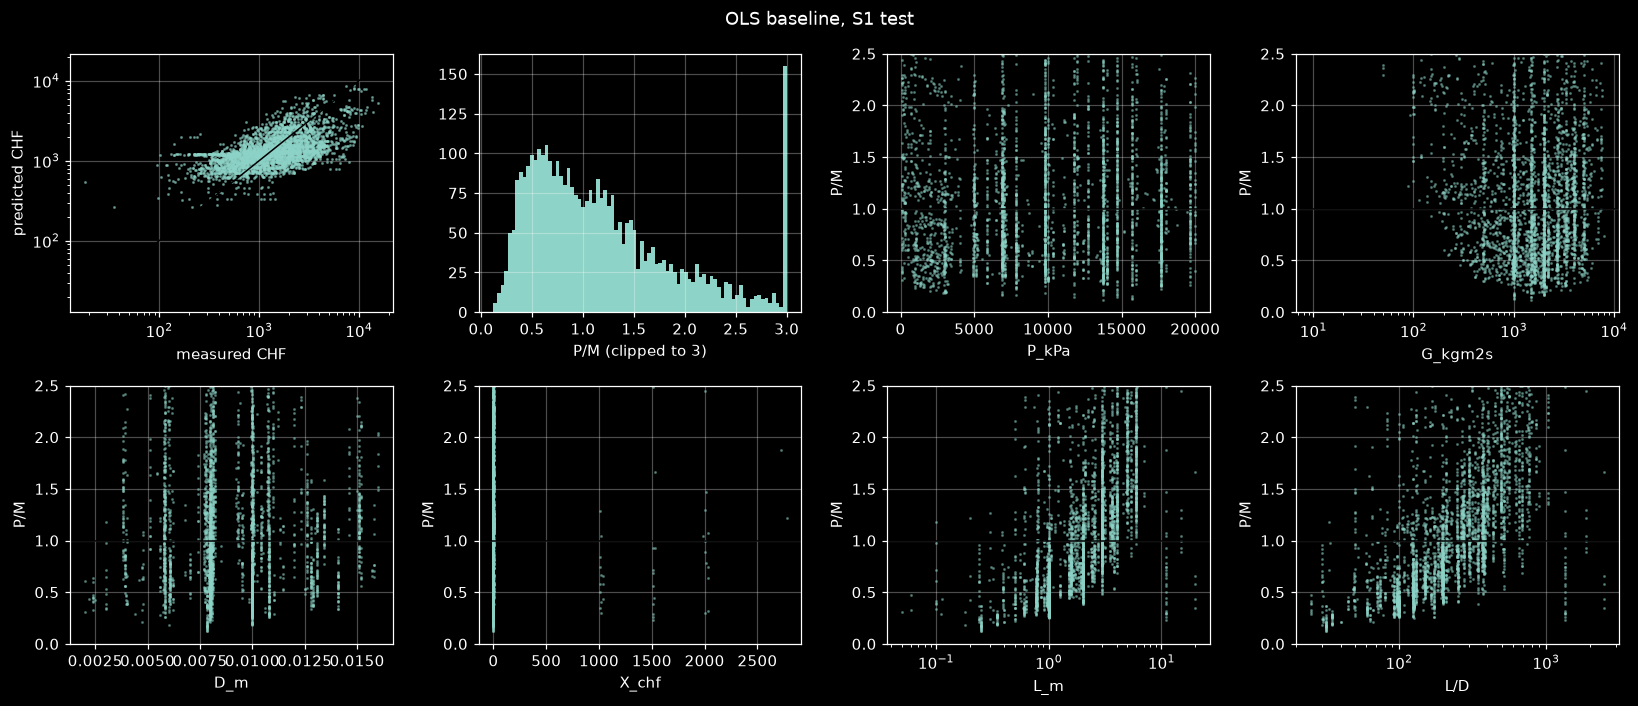

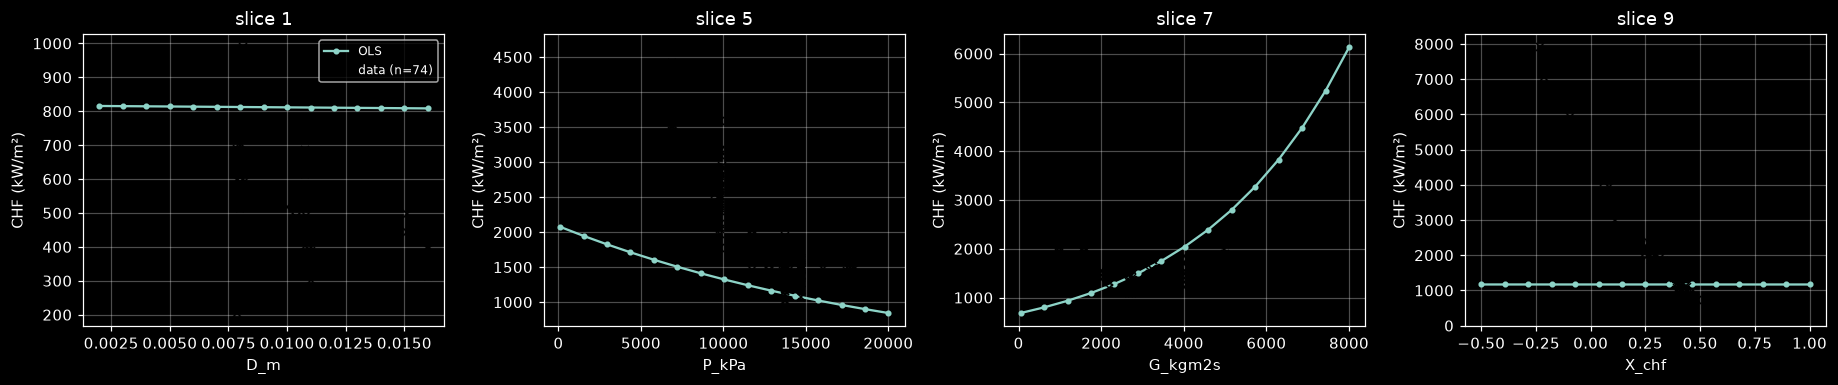

In [21]:
diagnostic_plots(S1["test"], ols(df.iloc[S1["test"]]), "OLS baseline, S1 test")
plot_slices({"OLS": ols})

### 1.11 Evaluating on S2 and S3

`evaluate_s2(fit_fn)` retrains your model in each of the five leave-sources-out folds and returns per-fold metrics plus mean ± std. Use the hyperparameters you chose on S1 validation; do not re-tune per fold.

In [14]:
def evaluate_s2(fit_fn, name):
    rows = []
    for k, (tr, te) in enumerate(S2):
        predict = fit_fn(tr)
        rows.append({"fold": k, **chf_metrics(df[TARGET].to_numpy()[te], predict(df.iloc[te]))})
    per_fold = pd.DataFrame(rows).set_index("fold")
    summary = per_fold.drop(columns="n").agg(["mean", "std"])
    RESULTS.append({"model": name, "split": "S2 (mean of 5 folds)", "n": int(per_fold["n"].sum()),
                    **summary.loc["mean"].to_dict()})
    return per_fold, summary

per_fold, summary = evaluate_s2(fit_ols_log, "OLS ln CHF (LOCAL)")
display(summary)

ols_s3 = fit_ols_log(S3["train"])
record("OLS ln CHF (LOCAL)", "S3 test", df[TARGET].to_numpy()[S3["test"]], ols_s3(df.iloc[S3["test"]]))
display(results_table())

,mean_PM,std_PM,RMSPE_%,MAPE_%,EQ2
mean,1.283,1.073,112.7,66.68,0.8416
std,0.2692,0.3989,42.69,15.68,0.05795


n  mean_PM  std_PM  RMSPE_%  \
model              split                                                   
OLS ln CHF (LOCAL) S1 val                 3687    1.293    1.18    121.5   
                   S1 test                3687    1.255   1.092    112.2   
                   low-G test             1013    1.567   1.569    166.8   
                   S2 (mean of 5 folds)  24579    1.283   1.073    112.7   
                   S3 test                3121    1.872   1.021    134.3   

                                         MAPE_%    EQ2  
model              split                                
OLS ln CHF (LOCAL) S1 val                 65.67 0.7683  
                   S1 test                62.33 0.7258  
                   low-G test             87.27 0.8813  
                   S2 (mean of 5 folds)   66.68 0.8416  
                   S3 test                98.12   1.67

### 1.12 Prediction files

Submit one file per task on the S1 test set. Lower and upper 95% bounds are required for Task B.

In [15]:
def save_chf_predictions(task, idx, y_pred, lower=None, upper=None, split_name="S1test"):
    """

    :param task:
    :param idx:
    :param y_pred:
    :param lower:
    :param upper:
    :param split_name:
    :return:
    """
    out = pd.DataFrame({"Number": df["Number"].to_numpy()[idx],
                        "y_true": df[TARGET].to_numpy()[idx],
                        "y_pred": np.asarray(y_pred, float)})
    if lower is not None:
        out["lower_95"], out["upper_95"] = np.asarray(lower, float), np.asarray(upper, float)
    path = OUT_DIR / f"pred_{task}_{split_name}.csv"
    out.to_csv(path, index=False)
    print("saved", path, out.shape)

save_chf_predictions("baseline", S1["test"], ols(df.iloc[S1["test"]]))

saved outputs\pred_baseline_S1test.csv (3687, 3)


### Where to go next (Tasks A–D)

- **Task A.** Write `fit_mlp(train_idx)` in the same form as `fit_ols_log`, tune it on `S1["val"]`, then call `record`, `diagnostic_plots`, `plot_slices` and `evaluate_s2`. For A4 use `INLET`, and `check_features(..., allow_leaky=True)` for the leakage demonstration.
- **Task B.** `get_xy(np.random.default_rng(SEED).choice(S1["train"], 2000, replace=False))` gives an exact-GP subset. Report `uq_metrics_gaussian` and `calibration_curve_gaussian` on `S1["test"]` and `S3["test"]`; save bounds with `save_chf_predictions(..., lower=, upper=)`.
- **Task C.** For the data-scarcity study draw subsets with `np.random.default_rng(seed).choice(S1["train"], int(frac * len(S1["train"])), replace=False)` for seeds 0, 1, 2. For collocation points sample uniformly over *P* 100–20,000 kPa, *G* 50–8000, *D* 0.002–0.016 m, *x* −0.5 to 1.0.
- **Task D.** Train on `df.iloc[S1["train"]][GEN_COLS]`. Compare samples with `df.iloc[S1["test"]]` using `marginal_w1`, `c2st_auc` and `nonphysical_fraction`; sample along slices with `make_slice(7)` and `make_slice(9)` as conditions.

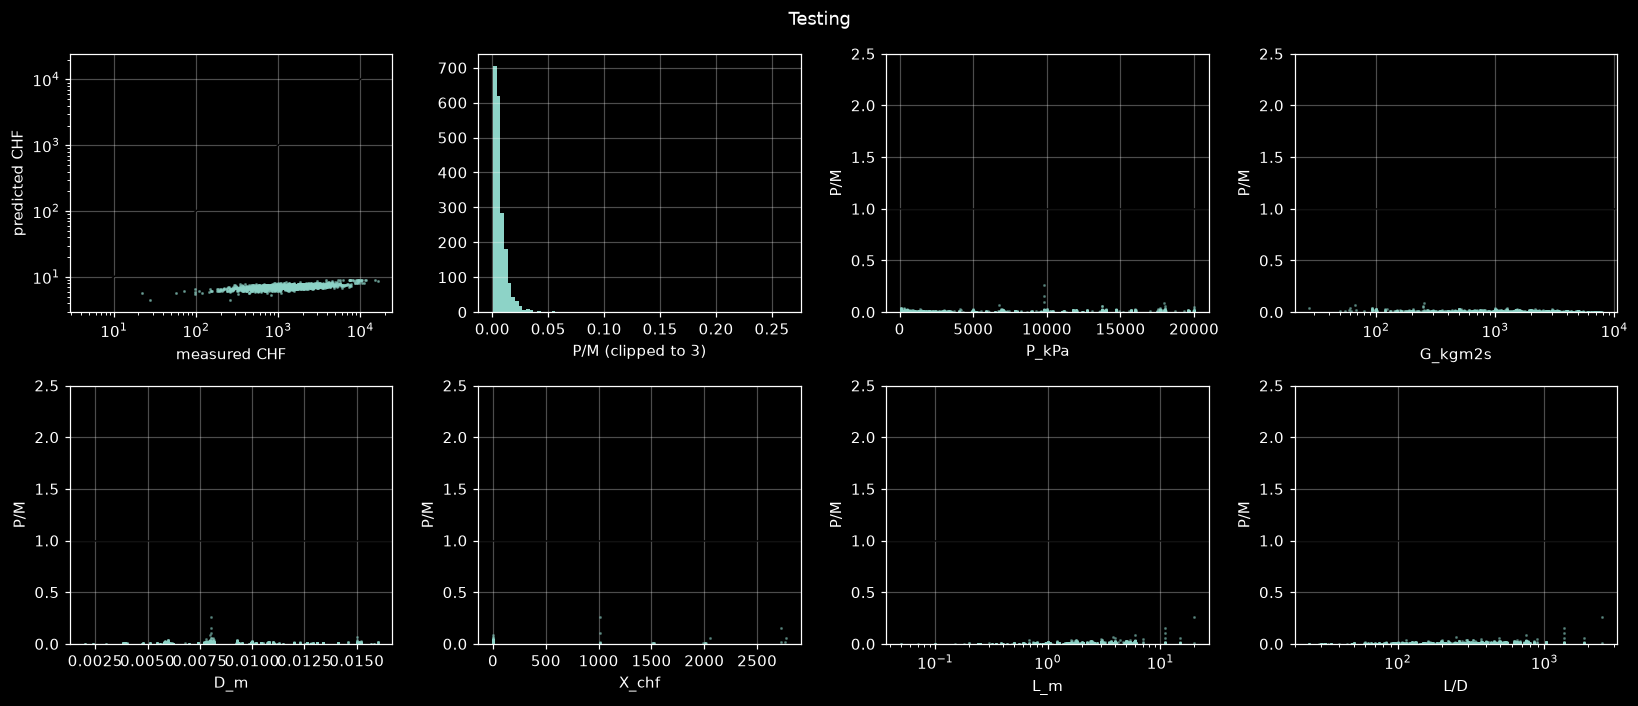

In [20]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF

subsets = [500, 2000, 5000]

X,Y = get_xy(np.random.default_rng(SEED).choice(S1["train"], 2000, replace=False))

kernel = 1 * RBF()
gaussian_process = GaussianProcessRegressor(kernel=kernel, alpha=0.5**2, n_restarts_optimizer=9)
gaussian_process.fit(X, Y)
gaussian_process.kernel_

mean_prediction, std_prediction = gaussian_process.predict(X, return_std=True)

chf_metrics(Y, mean_prediction)

diagnostic_plots(np.random.default_rng(SEED).choice(S1["train"], 2000, replace=False), mean_prediction, "Testing")